# Step 5c — Spatial transferability test (SVM vs GAEZ, longitude-band blocked holdout)

**Question**: does the SVM's climate->presence relationship, fit on one part of Europe, generalize
to a geographically distinct part it never saw during training -- or does it only work because it
gets to see (and partly memorize the climate signature of) every region at training time?

**Design**: split the training grid into 4 contiguous longitude bands (not a single arbitrary
East/West split -- a blocked design avoids cherry-picking one convenient boundary, and keeps spatial
autocorrelation from leaking between train/test like a random point-wise split would). For each band
in turn: retrain the SVM using Andrea's two-pass method (same procedure as
`3)_SVM_train_ERA5_MIRCA2000_threshold5pct.ipynb`) on the *other three* bands only, then predict on the held-out band and
score AUC against MIRCA2000. **Hyperparameters (cost, gamma) are reused from the already-tuned full
model** (`svm_train_outputs/svm_model_<crop>.joblib`) rather than re-run per fold -- this tests
generalization of the fitted decision boundary, not hyperparameter sensitivity; re-tuning per fold
would be a different (nested-CV) question and much more expensive.

**GAEZ v5 is included as a control**, exactly as in the temporal test
([5.b)_SVM_temporal_transferability.ipynb](../5.e\)_SVM_temporal_transferability/5.b\)_SVM_temporal_transferability.ipynb)): GAEZ is never
fit to any region's MIRCA data, so its band-level AUC is a location-independent reference point.

**Reading the result**: compare each band's held-out AUC to the reference non-spatial 10-fold CV AUC
already reported in `3)_SVM_train_ERA5_MIRCA2000_threshold5pct.ipynb` (`cv_results_<crop>.csv`, random point-wise folds, so
spatial autocorrelation lets nearby points leak between train/test -- an optimistic reference). A
held-out band AUC close to that reference is good evidence of spatial transferability; a large,
consistent drop (especially concentrated in specific bands) points to regional overfitting.


In [1]:
import os; os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")   # BDAP/EOS refuses HDF5 file locks ("NetCDF: HDF error")
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, joblib, rasterio
from rasterio.windows import Window
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

BASE        = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "0_Input_data").is_dir())  # racine du projet (local ou BDAP)
import sys; sys.path.insert(0, str(BASE)); import crop_utils as cu   # helpers + config reader (project root)
CFG = cu.load_config()   # config/config_<profile>.json, written by 00_config_and_inventory.ipynb
ERA5_DIR    = BASE / "1_SVM" / "1_preprocessing_BIOvariables" / "1.1)_preprocessing_biovariables_ERA5" / "outputs_ERA5_MIRCA2000_threshold5pct"
MODEL_DIR   = BASE / "1_SVM" / "3_SVM_train" / "3.a)_SVM_train_ERA5_MIRCA2000_threshold5pct" / "svm_train_outputs_mirca2000_threshold5pct"
GAEZ_DIR    = cu.data_dir(CFG, "gaez_v5_hist")  # data path: see 00_config_and_inventory.ipynb
OUT_DIR     = BASE / "1_SVM" / "5_Suitability_climate_soil_combined_validation" / "5.f)_SVM_spatial_transferability" / "spatial_transferability_outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

CROPS = ['Maize_rf', 'Wheat-spring_rf', 'Wheat-winter_rf', 'Potato_rf']
GAEZ_CODE = {'Maize_rf': 'MZE', 'Wheat-spring_rf': 'WHE', 'Wheat-winter_rf': 'WHE', 'Potato_rf': 'WPO'}
BIO_COLS = [f'BIO{i:02d}' for i in range(1, 13)]

# 4 contiguous longitude bands spanning the full -25..44 domain (merged from an initial 5-band
# split -- the westmost band [-25,-11) had zero MIRCA presence for every crop, so it is folded
# into its eastern neighbour here).
LON_BANDS = [(-25, 3), (3, 17), (17, 31), (31, 45)]
BAND_LABELS = [f'{a} to {b} E' for a, b in LON_BANDS]

print("Bands:", BAND_LABELS)

Bands: ['-25 to 3 E', '3 to 17 E', '17 to 31 E', '31 to 45 E']


## 1. Reused training routine (Andrea's two-pass oversampling, verbatim from `3)_SVM_train_ERA5_MIRCA2000_threshold5pct.ipynb`)

In [2]:
def kernel_similarity(anchor, pool, gamma):
    diff = anchor - pool
    row_sum = diff.sum(axis=1)
    sq_norm = np.sum(diff ** 2, axis=1)
    sim = np.exp(-gamma * sq_norm ** 2)
    sim[row_sum == 0] = np.nan
    return sim


def rbf_preimage(x_i, x_j, lam, gamma, n_iter=15, eps=1e-10):
    """Approximate RBF pre-image of (1-lam)*phi(x_i)+lam*phi(x_j), Mika et al. (1999)
    fixed-point iteration -- see 3)_SVM_train_ERA5_MIRCA2000_threshold5pct.ipynb for the full derivation."""
    x = (1 - lam) * x_i + lam * x_j
    for _ in range(n_iter):
        k_i = (1 - lam) * np.exp(-gamma * np.sum((x - x_i) ** 2))
        k_j = lam * np.exp(-gamma * np.sum((x - x_j) ** 2))
        denom = k_i + k_j
        if denom < eps:
            break
        x_new = (k_i * x_i + k_j * x_j) / denom
        if np.sum((x_new - x) ** 2) < eps:
            x = x_new
            break
        x = x_new
    return x


def fsmote(x, fulls, gamma, k, n_synth, rng):
    n_x = len(x)
    k = min(k, len(fulls) - 1)
    if n_synth < n_x:
        idx = rng.integers(0, n_x, size=n_synth)
        reps_per_point = np.ones(n_synth, dtype=int)
    else:
        idx = np.arange(n_x)
        reps_per_point = np.full(n_x, round(n_synth / n_x))
    synth = []
    for i, reps in zip(idx, reps_per_point):
        sim = kernel_similarity(x[i], fulls, gamma)
        neighbours = np.argsort(np.nan_to_num(sim, nan=-np.inf))[::-1][:k]  # largest similarity = nearest (reverted from R-literal farthest -- see 3)_SVM_train_ERA5_MIRCA2000_threshold5pct.ipynb docstring)
        chosen = rng.integers(0, len(neighbours), size=reps)
        for c in chosen:
            j = neighbours[c]
            lam = rng.uniform(0.0, 1.0)
            synth.append(rbf_preimage(x[i], fulls[j], lam, gamma))
    return np.array(synth) if synth else np.empty((0, x.shape[1]))


def fit_svm_two_pass(X, y, cost, gamma, rng):
    n_pos = int((y == 1).sum())
    n_neg = int((y == 0).sum())
    imb = n_pos / n_neg if n_neg > 0 else 1.0
    cw = {1: 1.0, 0: imb}
    svm1 = SVC(kernel='rbf', C=cost, gamma=gamma, class_weight=cw, random_state=42)
    svm1.fit(X, y)
    sv_idx = svm1.support_
    sv_y = y[sv_idx]
    n_sv_pos = int((sv_y == 1).sum())
    n_sv_neg = int((sv_y == 0).sum())
    n_add = n_sv_neg - n_sv_pos
    if n_add > 0 and n_sv_pos > 0:
        sv_pos = X[sv_idx][sv_y == 1]
        pool_pos = X[y == 1]
        synth = fsmote(sv_pos, pool_pos, gamma, k=5, n_synth=n_add, rng=rng)
        X_aug = np.vstack([X, synth])
        y_aug = np.concatenate([y, np.ones(len(synth), dtype=int)])
    else:
        X_aug, y_aug = X, y
    svm2 = SVC(kernel='rbf', C=cost, gamma=gamma, class_weight=cw, probability=True, random_state=42)
    svm2.fit(X_aug, y_aug)
    return svm2


print('Training routine ready (copied verbatim from 3)_SVM_train_ERA5_MIRCA2000_threshold5pct.ipynb).')

Training routine ready (copied verbatim from 3)_SVM_train_ERA5_MIRCA2000_threshold5pct.ipynb).


## 2. GAEZ v5 (control), 1deg -- same conversion as `5.a)`/`5.b)`

In [3]:
GAEZ_SI_MIDPOINTS = {0: np.nan, 1: 0.925, 2: 0.775, 3: 0.625, 4: 0.475, 5: 0.325,
                      6: 0.175, 7: 0.05, 8: 0.0, 9: np.nan}


def load_gaez_v5_six_1deg(path, target_lats_asc, target_lons, land_mask):
    nlat, nlon = len(target_lats_asc), len(target_lons)
    LAT_MIN_EDGE, LAT_MAX_EDGE = target_lats_asc[0] - 0.5, target_lats_asc[-1] + 0.5
    LON_MIN_EDGE, LON_MAX_EDGE = target_lons[0] - 0.5, target_lons[-1] + 0.5
    with rasterio.open(path) as src:
        res = src.transform.a
        ulx, uly = src.transform.c, src.transform.f
        px_per_deg = round(1.0 / res)
        col_start = round((LON_MIN_EDGE - ulx) / res)
        row_start = round((uly - LAT_MAX_EDGE) / res)
        col_count = round((LON_MAX_EDGE - LON_MIN_EDGE) / res)
        row_count = round((LAT_MAX_EDGE - LAT_MIN_EDGE) / res)
        raw = src.read(1, window=Window(col_start, row_start, col_count, row_count))
    score = np.vectorize(GAEZ_SI_MIDPOINTS.get)(raw).astype(float)
    blocks = score.reshape(nlat, px_per_deg, nlon, px_per_deg)
    with np.errstate(invalid='ignore'):
        out = np.nanmean(blocks, axis=(1, 3))[::-1, :]
    return np.where(land_mask, out, np.nan)


ds_grid = pd.read_pickle if False else None  # placeholder, real grid loaded per-crop below via xarray
import xarray as xr
ds0 = xr.open_dataset(ERA5_DIR / 'BIOvariables_ERA5_1981_2015_1deg_Maize_rf.nc')
target_lats_asc = ds0.lat.values
target_lons = ds0.lon.values
ds0.close()
land_mask = np.isfinite(xr.open_dataset(ERA5_DIR / 'BIOvariables_ERA5_1981_2015_1deg_Maize_rf.nc')['BIO01'].values)
li = {round(x, 1): i for i, x in enumerate(target_lats_asc)}
lj = {round(x, 1): j for j, x in enumerate(target_lons)}

gaez_1deg = {crop: load_gaez_v5_six_1deg(GAEZ_DIR / f'GAEZ-V5.RES05-SIX.HP8100.AGERA5.HIST.{GAEZ_CODE[crop]}.HRLM.tif',
                                          target_lats_asc, target_lons, land_mask)
             for crop in CROPS}
print('GAEZ v5 (control) loaded for', list(gaez_1deg.keys()))

GAEZ v5 (control) loaded for ['Maize_rf', 'Wheat-spring_rf', 'Wheat-winter_rf', 'Potato_rf']


## 3. Blocked spatial holdout: retrain excluding each band, evaluate on it

In [4]:
rows = []
rng_master = np.random.default_rng(42)

for crop in CROPS:
    df = pd.read_csv(ERA5_DIR / f'training_dataset_ERA5_1deg_{crop}.csv')
    bundle = joblib.load(MODEL_DIR / f'svm_model_{crop}.joblib')
    cost, gamma = bundle['best_cost'], bundle['best_gamma']

    # reference, non-spatial CV AUC already computed in 3)_SVM_train_ERA5_MIRCA2000_threshold5pct.ipynb (random point-wise
    # folds -- an optimistic baseline since nearby points can leak between train/test there)
    cv_df = pd.read_csv(MODEL_DIR / f'cv_results_{crop}.csv')
    ref_auc = cv_df.loc[(cv_df.cost == cost) & (cv_df.gamma == gamma), 'AUC'].values[0]

    df['band'] = pd.cut(df['lon'], bins=[b[0] for b in LON_BANDS] + [LON_BANDS[-1][1]], right=False,
                         labels=BAND_LABELS)

    gaez_arr = gaez_1deg[crop]
    ii_all = df.lat.round(1).map(li).values
    jj_all = df.lon.round(1).map(lj).values
    df['gaez'] = gaez_arr[ii_all, jj_all]

    for band_label in BAND_LABELS:
        test_mask = (df['band'] == band_label).values
        train_mask = ~test_mask
        X_tr = df.loc[train_mask, BIO_COLS].values.astype(float)
        y_tr = df.loc[train_mask, 'label'].values.astype(int)
        X_te = df.loc[test_mask, BIO_COLS].values.astype(float)
        y_te = df.loc[test_mask, 'label'].values.astype(int)
        n_pos_test = int(y_te.sum())

        if n_pos_test == 0 or n_pos_test == len(y_te):
            svm_auc = np.nan  # undefined: held-out band has only one class present
        else:
            scaler = StandardScaler()
            X_tr_s = scaler.fit_transform(X_tr)
            X_te_s = scaler.transform(X_te)
            clf = fit_svm_two_pass(X_tr_s, y_tr, cost, gamma, rng_master)
            y_prob = clf.predict_proba(X_te_s)[:, 1]
            svm_auc = roc_auc_score(y_te, y_prob)

        gaez_te = df.loc[test_mask, 'gaez'].values
        ok = np.isfinite(gaez_te)
        if n_pos_test == 0 or n_pos_test == len(y_te) or ok.sum() < 5:
            gaez_auc = np.nan
        else:
            gaez_auc = roc_auc_score(y_te[ok], gaez_te[ok])

        rows.append(dict(crop=crop, band=band_label, n=int(test_mask.sum()), n_presence=n_pos_test,
                          svm_auc=svm_auc, gaez_auc=gaez_auc, ref_auc_nonspatial=round(ref_auc, 3)))
        print(f"{crop:18s} {band_label:12s} n={test_mask.sum():4d} presence={n_pos_test:3d}  "
              f"SVM AUC={svm_auc if np.isnan(svm_auc) else round(svm_auc,3)}  "
              f"GAEZ AUC={gaez_auc if np.isnan(gaez_auc) else round(gaez_auc,3)}")

spatial_df = pd.DataFrame(rows)
spatial_df.to_csv(OUT_DIR / 'spatial_transferability_auc.csv', index=False)

Maize_rf           -25 to 3 E   n= 203 presence= 33  SVM AUC=0.916  GAEZ AUC=0.936


Maize_rf           3 to 17 E    n= 294 presence=114  SVM AUC=0.707  GAEZ AUC=0.837


Maize_rf           17 to 31 E   n= 400 presence=101  SVM AUC=0.843  GAEZ AUC=0.921


Maize_rf           31 to 45 E   n= 435 presence= 67  SVM AUC=0.912  GAEZ AUC=0.84


Wheat-spring_rf    -25 to 3 E   n= 203 presence= 36  SVM AUC=0.506  GAEZ AUC=0.586


...

Wheat-winter_rf    17 to 31 E   n= 400 presence=211  SVM AUC=0.951  GAEZ AUC=0.801


Wheat-winter_rf    31 to 45 E   n= 435 presence=226  SVM AUC=0.8  GAEZ AUC=0.657
Potato_rf          -25 to 3 E   n= 203 presence=  0  SVM AUC=nan  GAEZ AUC=nan


Potato_rf          3 to 17 E    n= 294 presence=  9  SVM AUC=0.365  GAEZ AUC=0.892


Potato_rf          17 to 31 E   n= 400 presence= 59  SVM AUC=0.806  GAEZ AUC=0.906


Potato_rf          31 to 45 E   n= 435 presence= 33  SVM AUC=0.874  GAEZ AUC=0.804


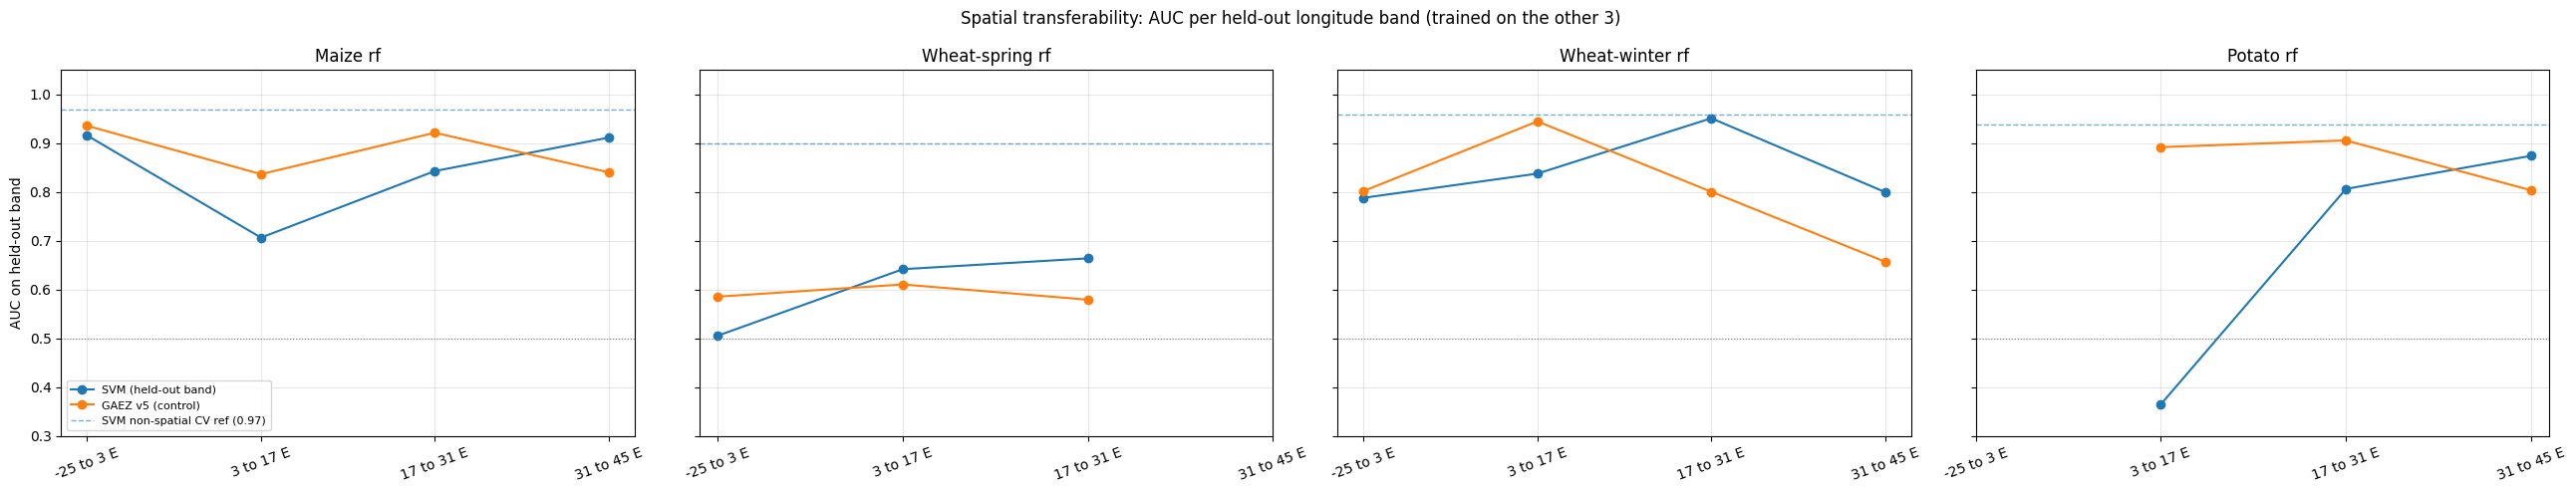

In [5]:
fig, axes = plt.subplots(1, len(CROPS), figsize=(6.5 * len(CROPS), 5), sharey=True)
x = np.arange(len(BAND_LABELS))
for ax, crop in zip(axes, CROPS):
    sub = spatial_df[spatial_df.crop == crop].set_index('band').loc[BAND_LABELS]
    ax.plot(x, sub['svm_auc'], marker='o', color='#1f77b4', label='SVM (held-out band)')
    ax.plot(x, sub['gaez_auc'], marker='o', color='#ff7f0e', label='GAEZ v5 (control)')
    ref = sub['ref_auc_nonspatial'].iloc[0]
    ax.axhline(ref, color='#1f77b4', linestyle='--', linewidth=1, alpha=0.6,
               label=f'SVM non-spatial CV ref ({ref:.2f})')
    ax.axhline(0.5, color='grey', linewidth=0.8, linestyle=':')
    ax.set_xticks(x); ax.set_xticklabels(BAND_LABELS, rotation=20)
    ax.set_title(crop.replace('_', ' '))
    ax.set_ylim(0.3, 1.05)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('AUC on held-out band')
axes[0].legend(loc='lower left', fontsize=8)
plt.suptitle('Spatial transferability: AUC per held-out longitude band (trained on the other 3)', fontsize=12)
plt.tight_layout()
plt.savefig(OUT_DIR / 'spatial_transferability_auc_by_band.png', dpi=130, bbox_inches='tight')
plt.show()

## Conclusion

Read each panel against its dashed reference line (the optimistic, non-spatial 10-fold CV AUC from
training): held-out-band AUC close to the reference line is evidence of good spatial transfer; a
systematic gap (especially concentrated in specific bands, e.g. the easternmost one) points to
regional overfitting -- the model's climate->presence mapping partly depends on having seen that
region's own examples, not just on climate values transferable from elsewhere. As in
[5.b)](../5.e\)_SVM_temporal_transferability/5.b\)_SVM_temporal_transferability.ipynb), GAEZ v5 is a location-independent control: if its
band-level AUC also varies similarly, that points to MIRCA2000 itself being harder to predict in
some bands for *any* method (soil/terrain/data-quality reasons), not something specific to the SVM's
spatial generalization.

NaN cells mean the held-out band has only one class present in MIRCA2000 (e.g. Wheat-spring_rf east
of 31E has zero recorded presence) -- AUC is undefined there; nothing to test transferability against
in that band for that crop. See [[svm-eastern-europe-gap-vs-gaez]] for the related temporal-vs-spatial
discussion and why this remains a historical proxy, not a true out-of-distribution climate test.
